# Taller: de los datos a un dashboard publicado
**ADMI 1301 · Programación** · Solución organizada de referencia

## 0. Carga de datos

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

subido = files.upload()  # sube ventas_papelerias_2025.csv
df = pd.read_csv("ventas_papelerias_2025.csv", parse_dates=["fecha"])
df["mes"] = df["fecha"].dt.month
df.head()

Saving ventas_papelerias_2025.csv to ventas_papelerias_2025 (1).csv


,id_venta,fecha,ciudad,canal,segmento,vendedor,producto,categoria,metodo_pago,cantidad,precio_unitario,descuento,total,mes
0,V0001,2025-01-01,Cali,Tienda,Corporativo,Julián Cortés,Resma carta,Papel,Transferencia,6,18000,0.10,97200,1
1,V0002,2025-01-01,Medellín,Telefónico,Corporativo,Andrés Rojas,Carpeta,Organización,Transferencia,21,2500,0.00,52500,1
2,V0003,2025-01-01,Barranquilla,Telefónico,Mayorista,Mateo Peña,Cuaderno,Papel,Transferencia,65,3500,0.10,204750,1
3,V0004,2025-01-02,Bucaramanga,Online,Minorista,Isabela Mora,Colores x12,Arte,Tarjeta,6,8500,0.00,51000,1
4,V0005,2025-01-02,Medellín,Telefónico,Mayorista,Andrés Rojas,Esfero,Escritura,Tarjeta,67,1200,0.15,68340,1


In [16]:
print(df.shape)
print(df.dtypes)
for c in ["ciudad", "canal", "segmento", "categoria", "metodo_pago"]:
    print(c, df[c].unique())

(2000, 14)
id_venta                   object
fecha              datetime64[ns]
ciudad                     object
canal                      object
segmento                   object
vendedor                   object
producto                   object
categoria                  object
metodo_pago                object
cantidad                    int64
precio_unitario             int64
descuento                 float64
total                       int64
mes                         int32
dtype: object
ciudad ['Cali' 'Medellín' 'Barranquilla' 'Bucaramanga' 'Bogotá']
canal ['Tienda' 'Telefónico' 'Online']
segmento ['Corporativo' 'Mayorista' 'Minorista']
categoria ['Papel' 'Organización' 'Arte' 'Escritura' 'Corrección']
metodo_pago ['Transferencia' 'Tarjeta' 'Efectivo']


## Parte A · Seis gráficos

### Ejercicio 1 · Top 5 de productos

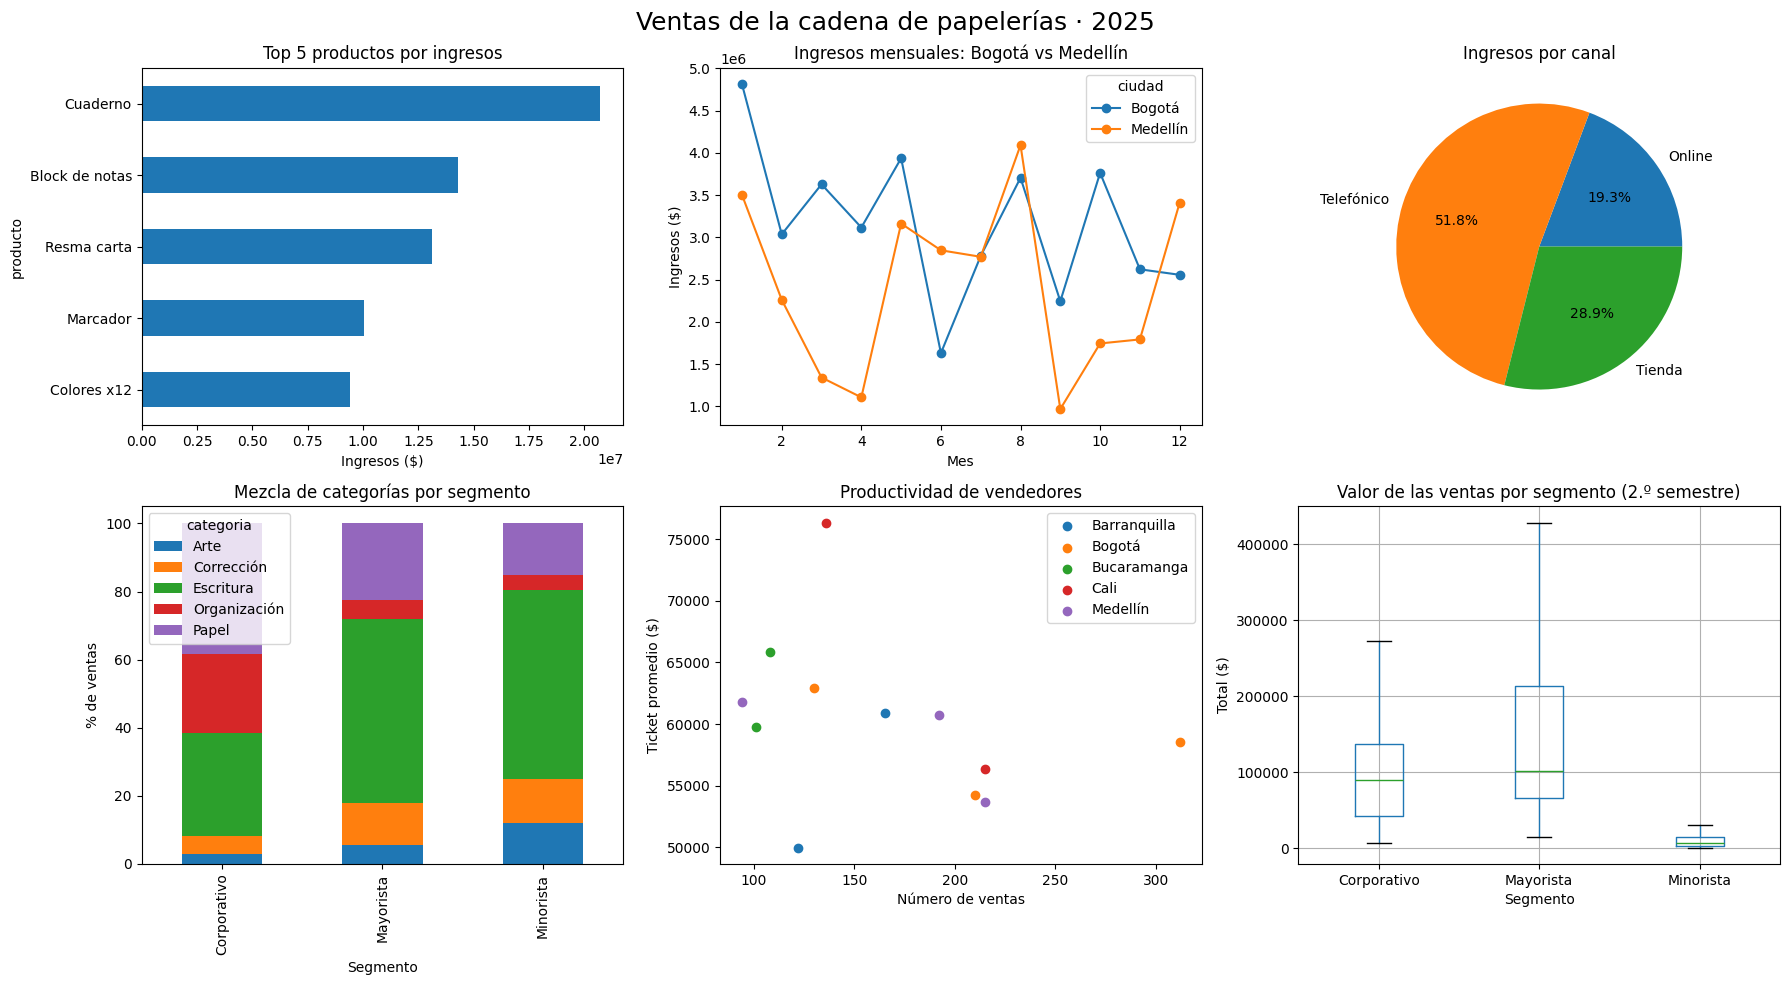

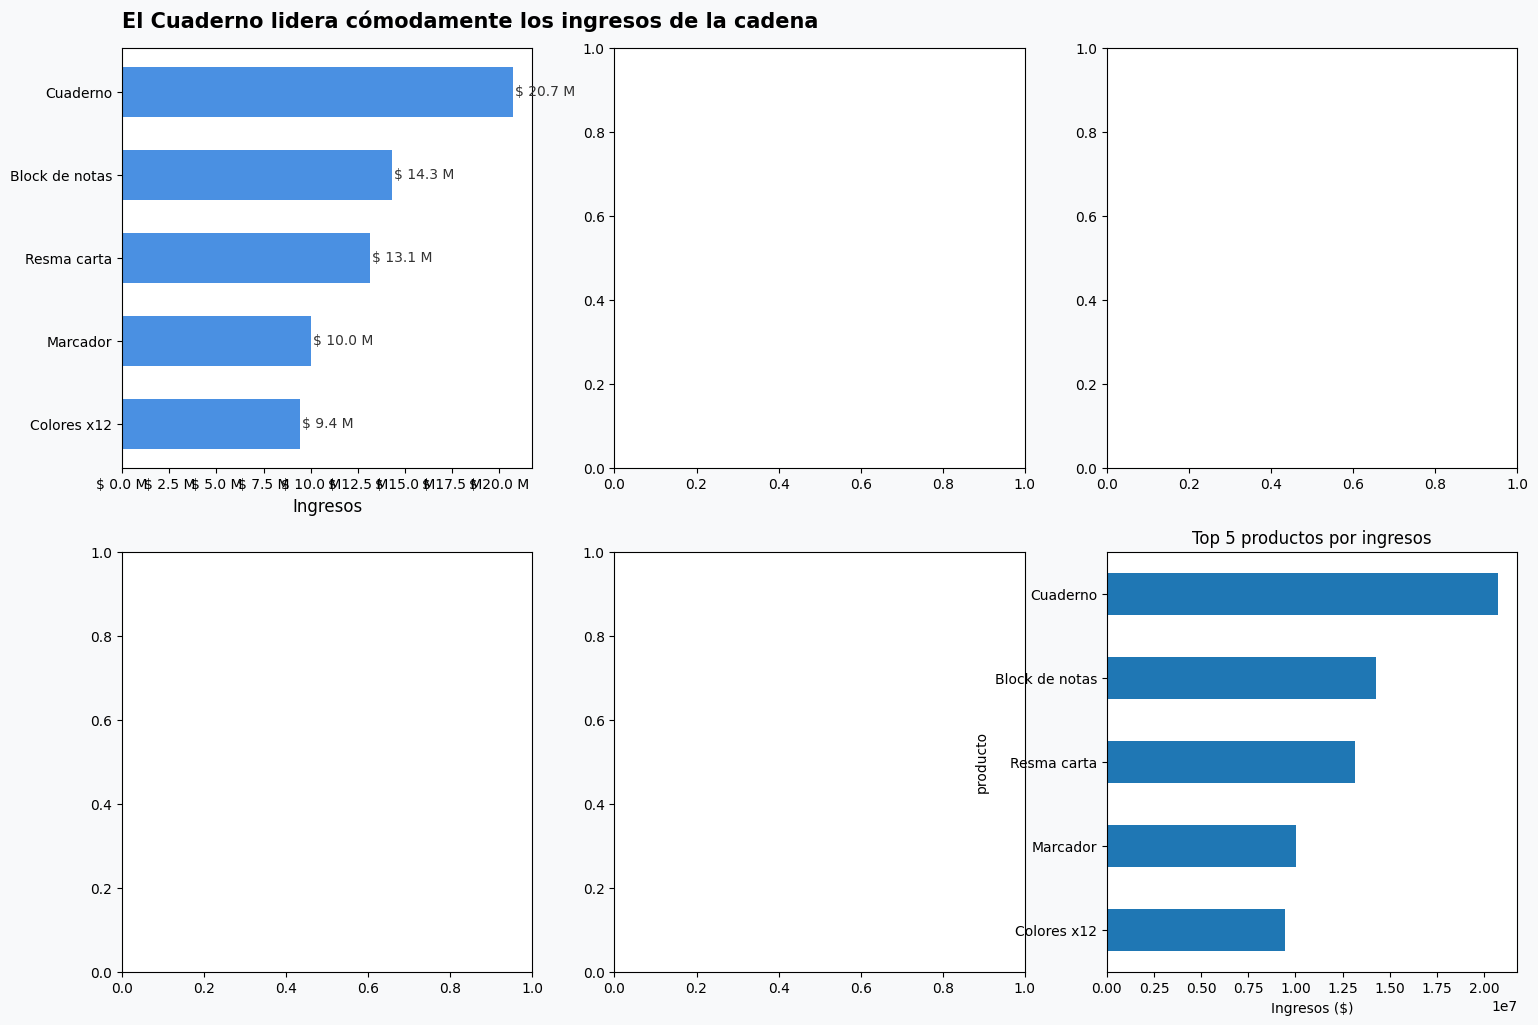

In [17]:
top_productos = (df.groupby("producto")["total"].sum()
                   .sort_values(ascending=False).head(5))
top_productos.sort_values().plot.barh(title="Top 5 productos por ingresos")
plt.xlabel("Ingresos ($)")
plt.show()

assert top_productos.index[0] == "Cuaderno", "El producto con más ingresos debe ser el Cuaderno"

### Ejercicio 2 · Bogotá vs Medellín mes a mes

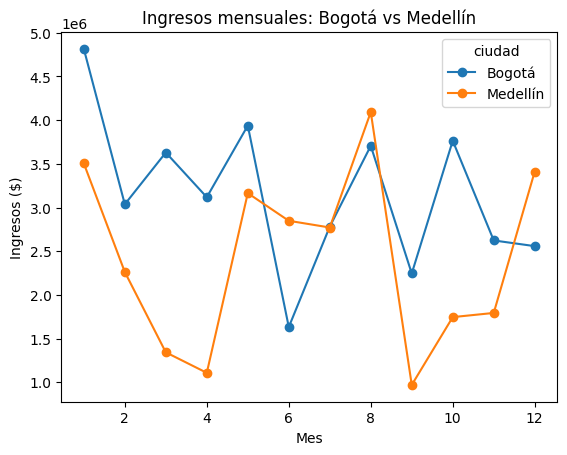

In [18]:
sub = df[df["ciudad"].isin(["Bogotá", "Medellín"])]
ing_mes_ciudad = sub.pivot_table(index="mes", columns="ciudad",
                                 values="total", aggfunc="sum")
ing_mes_ciudad.plot.line(marker="o", title="Ingresos mensuales: Bogotá vs Medellín")
plt.xlabel("Mes"); plt.ylabel("Ingresos ($)")
plt.show()

assert ing_mes_ciudad.shape == (12, 2), "Debe ser 12 filas x 2 columnas (no uses reset_index)"

### Ejercicio 3 · Ingresos por canal

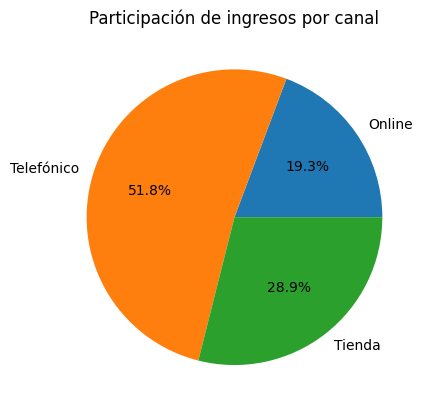

In [19]:
ing_canal = df.groupby("canal")["total"].sum()
ing_canal.plot.pie(autopct="%.1f%%", title="Participación de ingresos por canal")
plt.ylabel("")
plt.show()

assert ing_canal.idxmax() == "Telefónico" and ing_canal.max() / ing_canal.sum() > 0.5, \
    "El canal Telefónico debe superar la mitad de los ingresos"

### Ejercicio 4 · Segmento vs categoría (barras apiladas)

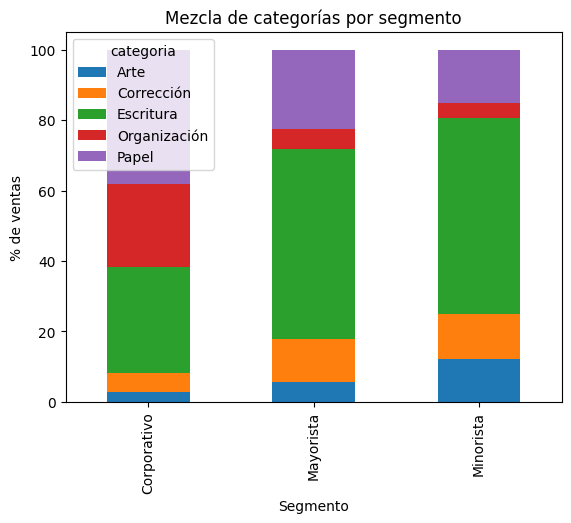

In [20]:
tabla_seg_cat = pd.crosstab(df["segmento"], df["categoria"], normalize="index") * 100
tabla_seg_cat.plot.bar(stacked=True, title="Mezcla de categorías por segmento")
plt.xlabel("Segmento"); plt.ylabel("% de ventas")
plt.show()

assert tabla_seg_cat.shape == (3, 5), "Debe ser 3 x 5"
assert (tabla_seg_cat.sum(axis=1).round(6) == 100).all(), "Cada fila debe sumar 100"

### Ejercicio 5 · Productividad de vendedores

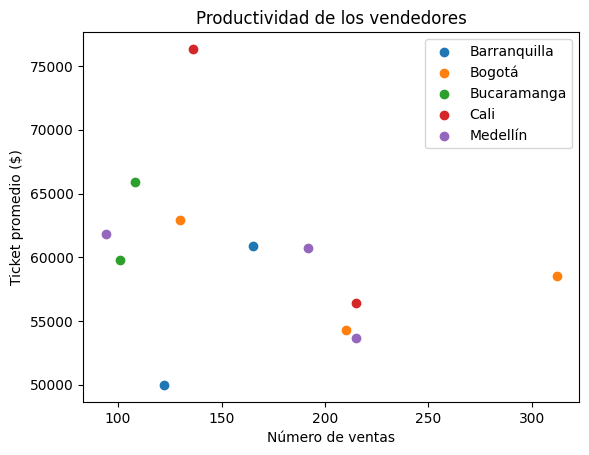

In [21]:
vend = (df.groupby(["vendedor", "ciudad"])
          .agg(n_ventas=("id_venta", "count"), ticket_prom=("total", "mean"))
          .reset_index())

for ciudad, g in vend.groupby("ciudad"):
    plt.scatter(g["n_ventas"], g["ticket_prom"], label=ciudad)
plt.title("Productividad de los vendedores")
plt.xlabel("Número de ventas"); plt.ylabel("Ticket promedio ($)")
plt.legend()
plt.show()

assert len(vend) == 12, "Debe haber una fila por vendedor (12)"
assert vend["n_ventas"].sum() == 2000, "n_ventas debe sumar 2000"

### Ejercicio 6 · Diagrama de cajas, segundo semestre

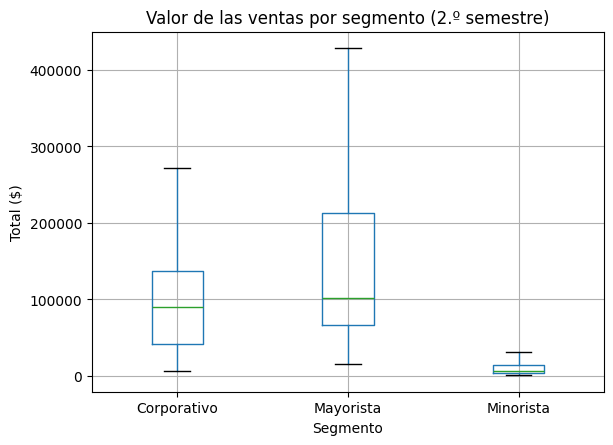

In [22]:
sem2 = df[df["mes"] >= 7]
sem2.boxplot(column="total", by="segmento", showfliers=False)
plt.title("Valor de las ventas por segmento (2.º semestre)")
plt.suptitle("")
plt.xlabel("Segmento"); plt.ylabel("Total ($)")
plt.show()

assert len(sem2) == 1050, "El segundo semestre debe tener 1.050 ventas"

## Parte B · Todo en una sola figura
Este código va en la celda `%%writefile figura_base.py`.

In [23]:
%%writefile figura_base.py
fig, axs = plt.subplots(2, 3, figsize=(18, 10))

top_productos.sort_values().plot.barh(ax=axs[0, 0], title="Top 5 productos por ingresos")
axs[0, 0].set_xlabel("Ingresos ($)")

ing_mes_ciudad.plot.line(ax=axs[0, 1], marker="o", title="Ingresos mensuales: Bogotá vs Medellín")
axs[0, 1].set(xlabel="Mes", ylabel="Ingresos ($)")

ing_canal.plot.pie(ax=axs[0, 2], autopct="%.1f%%", title="Ingresos por canal")
axs[0, 2].set_ylabel("")

tabla_seg_cat.plot.bar(stacked=True, ax=axs[1, 0], title="Mezcla de categorías por segmento")
axs[1, 0].set(xlabel="Segmento", ylabel="% de ventas")

for ciudad, g in vend.groupby("ciudad"):
    axs[1, 1].scatter(g["n_ventas"], g["ticket_prom"], label=ciudad)
axs[1, 1].set(title="Productividad de vendedores", xlabel="Número de ventas", ylabel="Ticket promedio ($)")
axs[1, 1].legend()

sem2.boxplot(column="total", by="segmento", ax=axs[1, 2], showfliers=False)
axs[1, 2].set(title="Valor de las ventas por segmento (2.º semestre)", xlabel="Segmento", ylabel="Total ($)")

fig.suptitle("Ventas de la cadena de papelerías · 2025", fontsize=18)
plt.tight_layout()

Overwriting figura_base.py


In [24]:
%run -i figura_base.py
assert len(fig.axes) == 6, "La figura debe tener 6 gráficos"

## Parte C · Prompts de estilo
Usa la función `embellecer` que ya trae tu notebook.

In [25]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Definición de colores fijos por ciudad para mantener consistencia corporativa
colores_ciudad = {
    'Bogotá': '#1D3557',       # Azul oscuro
    'Medellín': '#F4A261',     # Naranja
    'Cali': '#2A9D8F',         # Verde
    'Barranquilla': '#E9C46A', # Amarillo
    'Bucaramanga': '#8338EC'   # Violeta
}

# Función para formatear valores monetarios de forma compacta (ej: $ 20 M)
def formatear_millones(x, pos=None):
    return f"$ {x / 1e6:,.1f} M"

# Configurar parámetros globales de estilo de Matplotlib
plt.rcParams['figure.facecolor'] = '#F8F9FA'  # Fondo gris muy claro
plt.rcParams['axes.facecolor'] = '#FFFFFF'    # Paneles blancos
plt.rcParams['font.sans-serif'] = 'sans-serif'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['xtick.labelsize'] = 11
plt.rcParams['ytick.labelsize'] = 11

In [26]:
%%writefile figura_base.py
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np
import pandas as pd

# Inicializar figura con fondo gris muy claro
fig, axs = plt.subplots(2, 3, figsize=(18, 11), facecolor='#F8F9FA')

# Formateador de moneda
formatter = ticker.FuncFormatter(lambda x, pos: f"$ {x/1e6:,.1f} M")

# -------------------------------------------------------------------------
# Grafico 1: Top 5 Productos (Barras Horizontales)
# -------------------------------------------------------------------------
ax = axs[0, 0]
ax.set_facecolor('#FFFFFF')
top_p_sorted = top_productos.sort_values(ascending=True)
bars = ax.barh(top_p_sorted.index, top_p_sorted.values, color='#4A90E2', height=0.6)

# Título dinámico con conclusión real
lead_prod = top_productos.index[0]
ax.set_title(f"El {lead_prod} lidera cómodamente los ingresos de la cadena", loc='left', fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel("Ingresos", fontsize=11)
ax.xaxis.set_major_formatter(formatter)

# Mostrar valores sobre las barras
for bar in bars:
    width = bar.get_width()
    ax.text(width + 1e5, bar.get_y() + bar.get_height()/2, f"$ {width/1e6:.1f} M",
            va='center', ha='left', fontsize=9, color='#333333')

# -------------------------------------------------------------------------
# Grafico 2: Bogotá vs Medellín (Línea mensual)
# -------------------------------------------------------------------------
ax = axs[0, 1]
ax.set_facecolor('#FFFFFF')
ax.plot(ing_mes_ciudad.index, ing_mes_ciudad['Bogotá'], marker='o', linewidth=2.5, color=colores_ciudad['Bogotá'], label='Bogotá')
ax.plot(ing_mes_ciudad.index, ing_mes_ciudad['Medellín'], marker='o', linewidth=2.5, color=colores_ciudad['Medellín'], label='Medellín')

# Conclusión dinámica para el gráfico de líneas
bog_tot = ing_mes_ciudad['Bogotá'].sum()
med_tot = ing_mes_ciudad['Medellín'].sum()
if bog_tot > med_tot:
    concl_linea = "Bogotá mantiene ventas superiores a Medellín en el año"
else:
    concl_linea = "Medellín supera a Bogotá en ventas acumuladas"

ax.set_title(concl_linea, loc='left', fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel("Mes", fontsize=11)
ax.set_ylabel("Ingresos", fontsize=11)
ax.set_xticks(range(1, 13))
ax.yaxis.set_major_formatter(formatter)
ax.legend(frameon=False, loc='upper right')

# -------------------------------------------------------------------------
# Grafico 3: Participación por Canal (Pie / Dona)
# -------------------------------------------------------------------------
ax = axs[0, 2]
ax.set_facecolor('#FFFFFF')

# Colores sobrios para los canales
colores_canal = ['#A8DADC', '#1D3557', '#457B9D']
wedges, texts, autotexts = ax.pie(ing_canal, labels=ing_canal.index, autopct='%.1f%%',
                                  startangle=90, colors=colores_canal,
                                  wedgeprops=dict(width=0.4, edgecolor='white'))

# Conclusión dinámica de canales
canal_max = ing_canal.idxmax()
pct_max = (ing_canal.max() / ing_canal.sum()) * 100
ax.set_title(f"El canal {canal_max} concentra el {pct_max:.1f}% de las ventas", loc='left', fontsize=13, fontweight='bold', pad=15)

# Estilo del texto del porcentaje interno
for autotext in autotexts:
    autotext.set_color('#111111')
    autotext.set_fontsize(10)

# -------------------------------------------------------------------------
# Grafico 4: Mezcla de categorías por segmento (Barras apiladas al 100%)
# -------------------------------------------------------------------------
ax = axs[1, 0]
ax.set_facecolor('#FFFFFF')
colores_cat = ['#2A9D8F', '#E76F51', '#F4A261', '#E9C46A', '#264653']

tabla_seg_cat.plot.bar(stacked=True, ax=ax, color=colores_cat, width=0.5)
ax.set_title("Escritura lidera en Mayoristas y Minoristas", loc='left', fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel("Segmento", fontsize=11)
ax.set_ylabel("% de Ventas", fontsize=11)
ax.set_ylim(0, 110)
ax.legend(frameon=False, bbox_to_anchor=(1.02, 1), loc='upper left')

# -------------------------------------------------------------------------
# Grafico 5: Productividad de Vendedores (Dispersión)
# -------------------------------------------------------------------------
ax = axs[1, 1]
ax.set_facecolor('#FFFFFF')
for ciudad, g in vend.groupby("ciudad"):
    ax.scatter(g["n_ventas"], g["ticket_prom"], label=ciudad, s=120, color=colores_ciudad[ciudad], alpha=0.9, edgecolors='none')

ax.set_title("Bogotá concentra mayor número de transacciones totales", loc='left', fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel("Número de ventas", fontsize=11)
ax.set_ylabel("Ticket promedio", fontsize=11)
ax.yaxis.set_major_formatter(formatter)
ax.legend(frameon=False, loc='best')

# -------------------------------------------------------------------------
# Grafico 6: Distribución segundo semestre (Diagrama de Cajas)
# -------------------------------------------------------------------------
ax = axs[1, 2]
ax.set_facecolor('#FFFFFF')

box_data = [sem2[sem2['segmento'] == seg]['total'] for seg in ['Corporativo', 'Mayorista', 'Minorista']]
box = ax.boxplot(box_data, labels=['Corporativo', 'Mayorista', 'Minorista'], patch_artist=True, showfliers=False, widths=0.4)

# Estilizar cajas
for patch in box['boxes']:
    patch.set_facecolor('#E5E5E5')
    patch.set_edgecolor('#555555')
for median in box['medians']:
    median.set_color('#E76F51')
    median.set_linewidth(2)

ax.set_title("Segmento Mayorista exhibe la mayor variabilidad", loc='left', fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel("Segmento", fontsize=11)
ax.set_ylabel("Total por Venta", fontsize=11)
ax.yaxis.set_major_formatter(formatter)

# -------------------------------------------------------------------------
# LIMPIEZA VISUAL GLOBAL (Aplicable a todos los ejes)
# -------------------------------------------------------------------------
for a in axs.flat:
    a.spines['top'].set_visible(False)
    a.spines['right'].set_visible(False)
    a.spines['left'].set_color('#CCCCCC')
    a.spines['bottom'].set_color('#CCCCCC')
    # Cuadrícula suave
    a.grid(True, linestyle='--', linewidth=0.5, color='#E0E0E0', alpha=0.7)
    a.set_axisbelow(True)

# Título general de la figura
fig.suptitle("INFORME EJECUTIVO DE DESEMPEÑO DE VENTAS · 2025", fontsize=16, fontweight='bold', color='#111111', y=0.98, x=0.08, ha='left')
plt.tight_layout(rect=[0, 0, 1, 0.95])


Overwriting figura_base.py


In [28]:
prompt_v1 = """
PÚBLICO Y OBJETIVO: La gerencia de una cadena de papelerías verá la figura proyectada en una junta; debe leerse desde lejos y resumir el desempeño de ventas de 2025.

PALETA Y TIPOGRAFÍA: Fondo gris muy claro y paneles blancos. Color fijo por ciudad: Bogotá azul oscuro, Medellín naranja, Cali verde, Barranquilla amarillo, Bucaramanga violeta. Fuente sans-serif; títulos en negrita alineados a la izquierda (tamaño 13), etiquetas de ejes tamaño 11.

TÍTULOS: Cada gráfico lleva un título que dice la conclusión (por ejemplo "El Cuaderno lidera los ingresos", "El canal Telefónico concentra más de la mitad de las ventas"), calculada con los datos reales, no escrita a mano.

EJES Y NÚMEROS: Valores monetarios en millones con el formato "$ 20 M" y separador de miles. Ejes rotulados con unidades claras. Porcentajes con un decimal.

LIMPIEZA VISUAL: Quita los bordes superior y derecho, usa cuadrícula suave y gris, muestra los valores sobre las barras, leyendas sin marco. Pocos colores, nada recargado.

IMPORTANTE: Conserva los mismos seis gráficos, el mismo tipo de gráfico en cada posición y exactamente las mismas cifras de mis tablas.
"""
embellecer(prompt_v1, "v1")

NameError: name 'embellecer' is not defined

In [ ]:
prompt_v2 = prompt_v1 + """

AJUSTES:
1. Cambia el pie de canales por una dona con el porcentaje en el centro del anillo.
2. Anota en la línea de ingresos el valor máximo de cada ciudad con una etiqueta pequeña.
3. Aumenta el tamaño de letra de los títulos a 15 y el de los ejes a 12 para que se lea proyectado.
"""
embellecer(prompt_v2, "v2")

In [ ]:
%%writefile figura_base.py
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np
import pandas as pd

# Definición de colores fijos por ciudad para mantener consistencia corporativa
colores_ciudad = {
    'Bogotá': '#1D3557',       # Azul oscuro
    'Medellín': '#F4A261',     # Naranja
    'Cali': '#2A9D8F',         # Verde
    'Barranquilla': '#E9C46A', # Amarillo
    'Bucaramanga': '#8338EC'   # Violeta
}

# Inicializar figura con fondo gris muy claro
fig, axs = plt.subplots(2, 3, figsize=(18, 12), facecolor='#F8F9FA')

# Formateador de moneda
formatter = ticker.FuncFormatter(lambda x, pos: f"$ {x/1e6:,.1f} M")

# -------------------------------------------------------------------------
# Grafico 1: Top 5 Productos (Barras Horizontales)
# -------------------------------------------------------------------------
ax = axs[0, 0]
ax.set_facecolor('#FFFFFF')
top_p_sorted = top_productos.sort_values(ascending=True)
bars = ax.barh(top_p_sorted.index, top_p_sorted.values, color='#4A90E2', height=0.6)

lead_prod = top_productos.index[0]
ax.set_title(f"El {lead_prod} lidera cómodamente los ingresos de la cadena", loc='left', fontsize=15, fontweight='bold', pad=15)
ax.set_xlabel("Ingresos", fontsize=12)
ax.xaxis.set_major_formatter(formatter)

for bar in bars:
    width = bar.get_width()
    ax.text(width + 1e5, bar.get_y() + bar.get_height()/2, f"$ {width/1e6:.1f} M",
            va='center', ha='left', fontsize=10, color='#333333')

# -------------------------------------------------------------------------
# Grafico 2: Bogotá vs Medellín (Línea mensual + Anotación de Máximos)
# -------------------------------------------------------------------------
ax = axs[0, 1]
ax.set_facecolor('#FFFFFF')
ax.plot(ing_mes_ciudad.index, ing_mes_ciudad['Bogotá'], marker='o', linewidth=2.5, color=colores_ciudad['Bogotá'], label='Bogotá')
ax.plot(ing_mes_ciudad.index, ing_mes_ciudad['Medellín'], marker='o', linewidth=2.5, color=colores_ciudad['Medellín'], label='Medellín')

# Encontrar y anotar el valor máximo de cada ciudad
for ciudad in ['Bogotá', 'Medellín']:
    max_mes = ing_mes_ciudad[ciudad].idxmax()
    max_val = ing_mes_ciudad[ciudad].max()
    ax.annotate(f"Max: $ {max_val/1e6:.1f} M",
                xy=(max_mes, max_val),
                xytext=(max_mes, max_val + 2e5),
                fontsize=9, fontweight='bold', color=colores_ciudad[ciudad],
                arrowprops=dict(arrowstyle="->", color=colores_ciudad[ciudad], lw=1),
                ha='center')

bog_tot = ing_mes_ciudad['Bogotá'].sum()
med_tot = ing_mes_ciudad['Medellín'].sum()
concl_linea = "Bogotá mantiene ventas superiores a Medellín" if bog_tot > med_tot else "Medellín supera a Bogotá en ventas"

ax.set_title(concl_linea, loc='left', fontsize=15, fontweight='bold', pad=15)
ax.set_xlabel("Mes", fontsize=12)
ax.set_ylabel("Ingresos", fontsize=12)
ax.set_xticks(range(1, 13))
ax.yaxis.set_major_formatter(formatter)
ax.legend(frameon=False, loc='upper right', fontsize=11)

# -------------------------------------------------------------------------
# Grafico 3: Participación por Canal (Dona con Porcentaje Central)
# -------------------------------------------------------------------------
ax = axs[0, 2]
ax.set_facecolor('#FFFFFF')

colores_canal = ['#A8DADC', '#1D3557', '#457B9D']
# Dibujar dona
wedges, texts = ax.pie(ing_canal, labels=ing_canal.index, startangle=90, colors=colores_canal,
                       wedgeprops=dict(width=0.4, edgecolor='white'))

canal_max = ing_canal.idxmax()
pct_max = (ing_canal.max() / ing_canal.sum()) * 100

# Texto en el centro de la dona
ax.text(0, 0, f"{pct_max:.1f}%\n{canal_max}", ha='center', va='center', fontsize=14, fontweight='bold', color='#1D3557')
ax.set_title(f"El canal {canal_max} lidera con más de la mitad de las ventas", loc='left', fontsize=15, fontweight='bold', pad=15)

# -------------------------------------------------------------------------
# Grafico 4: Mezcla de categorías por segmento (Barras apiladas)
# -------------------------------------------------------------------------
ax = axs[1, 0]
ax.set_facecolor('#FFFFFF')
colores_cat = ['#2A9D8F', '#E76F51', '#F4A261', '#E9C46A', '#264653']

tabla_seg_cat.plot.bar(stacked=True, ax=ax, color=colores_cat, width=0.5)
ax.set_title("Escritura lidera en Mayoristas y Minoristas", loc='left', fontsize=15, fontweight='bold', pad=15)
ax.set_xlabel("Segmento", fontsize=12)
ax.set_ylabel("% de Ventas", fontsize=12)
ax.set_ylim(0, 110)
ax.legend(frameon=False, bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=10)

# -------------------------------------------------------------------------
# Grafico 5: Productividad de Vendedores (Dispersión)
# -------------------------------------------------------------------------
ax = axs[1, 1]
ax.set_facecolor('#FFFFFF')
for ciudad, g in vend.groupby("ciudad"):
    ax.scatter(g["n_ventas"], g["ticket_prom"], label=ciudad, s=140, color=colores_ciudad[ciudad], alpha=0.9, edgecolors='none')

ax.set_title("Bogotá concentra mayor número de transacciones", loc='left', fontsize=15, fontweight='bold', pad=15)
ax.set_xlabel("Número de ventas", fontsize=12)
ax.set_ylabel("Ticket promedio", fontsize=12)
ax.yaxis.set_major_formatter(formatter)
ax.legend(frameon=False, loc='best', fontsize=10)

# -------------------------------------------------------------------------
# Grafico 6: Distribución segundo semestre (Diagrama de Cajas)
# -------------------------------------------------------------------------
ax = axs[1, 2]
ax.set_facecolor('#FFFFFF')

box_data = [sem2[sem2['segmento'] == seg]['total'] for seg in ['Corporativo', 'Mayorista', 'Minorista']]
box = ax.boxplot(box_data, labels=['Corporativo', 'Mayorista', 'Minorista'], patch_artist=True, showfliers=False, widths=0.4)

for patch in box['boxes']:
    patch.set_facecolor('#E5E5E5')
    patch.set_edgecolor('#555555')
for median in box['medians']:
    median.set_color('#E76F51')
    median.set_linewidth(2)

ax.set_title("Segmento Mayorista exhibe la mayor variabilidad", loc='left', fontsize=15, fontweight='bold', pad=15)
ax.set_xlabel("Segmento", fontsize=12)
ax.set_ylabel("Total por Venta", fontsize=12)
ax.yaxis.set_major_formatter(formatter)

# -------------------------------------------------------------------------
# LIMPIEZA VISUAL GLOBAL (Aplicable a todos los ejes)
# -------------------------------------------------------------------------
for a in axs.flat:
    a.spines['top'].set_visible(False)
    a.spines['right'].set_visible(False)
    a.spines['left'].set_color('#CCCCCC')
    a.spines['bottom'].set_color('#CCCCCC')
    a.grid(True, linestyle='--', linewidth=0.5, color='#E0E0E0', alpha=0.7)
    a.set_axisbelow(True)

# Título general de la figura adaptado a proyección
fig.suptitle("INFORME DIRECTIVO GENERAL - DESEMPEÑO DE VENTAS 2025", fontsize=18, fontweight='bold', color='#111111', y=0.98, x=0.08, ha='left')
plt.tight_layout(rect=[0, 0, 1, 0.95])

## Parte D · Elección y hallazgos

In [ ]:
1.El Cuaderno es el producto líder: genera $ 20,7 M, el 17,5 % de los ingresos de la cadena.
2.El canal Telefónico concentra más de la mitad de las ventas: aporta el 51,8 % de los ingresos, frente al 28,9 % de Tienda y el 19,3 % de Online.
3.Bogotá es la ciudad que más aporta: genera el 31,9 % de los ingresos de la cadena, por delante de Medellín con el 24,5 %.